# 제12교시. 이상탐지 기반 위험상태 모니터링

### AXIA D12 · ROS 2 Jazzy 진단 이벤트 · 사건 시간선 · 운영자 피드백

> **오늘의 사건** — 관제 화면에 `WARNING`이 나타났습니다. *정말 로봇이 멈췄을까요?* 우리는 이벤트의 출처를 확인하고, 데이터를 검증하고, 판단 이유를 기록해야 합니다.  
> **실습 데이터:** `SYNTHETIC_COURSE_FIXTURE` **합성 교육자료 12건**. `EDUCATION_TRANSPORT_DEMO`의 점수는 **실제 IF/AE 추론 결과가 아닙니다.**  
> **안전 경계:** Python 오프라인 교육 실습만 수행합니다. **Nav2 Goal, `/cmd_vel`, 실제 SW Stop 및 인증된 E-Stop**과 연결하지 않습니다.

**학습 대상:** AI·Python·ROS 2 초심자/중급자 · **교육 시간:** 180분(이론 60분 + 실습 120분) · **선수지식:** D09(Trace·Window), D10(IF), D11(AE). 학습 이해를 위한 작은 실습은 선수 교시 모델을 다시 학습하지 않고 독립적으로 진행합니다.

## 1. 이번 교시의 학습 목표

| 목표 | 배운 뒤 할 수 있어야 하는 말·행동 | 평가할 증거 |
|---|---|---|
| **목표 ① 모니터링 구조 이해** | 합성 데이터 → JSONL → 유효성 검사 → 교육용 ROS `DiagnosticArray` *페이로드* → 관찰 화면의 인과관계를 설명 | `event_id`·시간 기준·진단 수준 4개의 의미를 설명하고 검증 |
| **목표 ② 시각화·피드백 실습** | 위험 이벤트 시간선과 상태별 비율을 그린 뒤, WARNING과 품질 부족을 구별하여 운영자 의견 작성 | 사건 타임라인, 분포 그래프, `operator_feedback.jsonl` 2건 검증 |

**오늘의 성공:** 단순한 '실행 성공'이 아니라 **사건의 근거를 다른 사람에게 설명할 수 있음**입니다. `[PASS]`는 Python에서 실제 `assert`가 모두 통과한 범위에만 표시합니다.

## 2. 핵심 용어 — 처음 등장하는 개념은 한 줄로 정리합니다

| 용어 | 뜻 | AXIA 예시 |
|---|---|---|
| **Trace(추적 구간)** | 하나의 시나리오에서 연속 수집한 기록 묶음 | `TST_N_00` |
| **Window(윈도우)** | Trace의 연속 샘플을 작은 구간으로 나눈 것 | D09에서 10샘플씩 특징 추출 |
| **JSONL(JSON Lines)** | 한 줄에 JSON 객체 하나를 저장하는 형식 | `sample_events.jsonl`: 12줄 → 12개 사건 |
| **Event ID(사건 식별자)** | 개별 사건을 구분하는 고유 문자열 | `DEMO:TST_N_00:002` |
| **Risk score(이상 점수)** | 해당 교육 프로필에서 이상 후보를 표시하는 수 | `0.9` (임의 점수) |
| **Threshold(임계값)** | 점수와 비교하는 구분 기준 | `0.5` |
| **Data quality(데이터 품질)** | 판정에 필요한 입력이 충분한가 | `INSUFFICIENT_DATA` / `risk_score=None` |
| **Publisher/Subscriber(발행/구독)** | ROS 토픽에 메시지를 전송/수신하는 노드 | 기존 교육 Bridge / Probe |
| **DiagnosticArray(진단 상태 묶음)** | ROS `diagnostic_msgs`의 진단 메시지 | `status[]`에 level 등 기록 |
| **Monotonic clock(단조 시계)** | 같은 프로세스에서 경과 시간을 비교하는 시계 | 수신 간격 계산 |
| **EventGate(사건 진입 검사)** | 중복·역행·시간 경계를 검사하는 코드 | 공개 `event_contract.py` |
| **Operator feedback(운영자 피드백)** | 사람이 확인한 조치·이유·시각 기록 | `operator_feedback.jsonl` |

**구별해야 할 말:** `WARNING`은 교육용 판정 정보입니다. 실제 로봇의 **SW 정지** 및 **인증된 E-Stop**과 같지 않습니다.

## 3. 수업 진행표 · 6단계 학습 루트

| 시간 | 학습 단계 | 직접 수행할 결과 |
|---|---|---|
| 19:00–19:35 | **STEP 1** · 문제·출처·원본 읽기 | 이벤트 12건·원본 SHA·데이터 shape |
| 19:35–20:00 | **STEP 2** · 임계값과 네 상태 | 경계 조건·품질 누락을 `assert`로 확인 |
| 20:00–20:20 | **STEP 3** · 시간·중복·EventGate | 중복/역행과 monotonic 시험 |
| 20:20–20:45 | **STEP 4** · ROS 진단 페이로드 구조 | 0/1/2/3과 `DiagnosticArray` 구조 대응 |
| 20:45–21:20 | **STEP 5** · 시간선/분포 시각화 | 그래프 2개와 정량 집계 |
| 21:20–21:50 | **STEP 6** · 운영자 피드백 기록 | JSONL 2건 저장·재읽기·불변 조건 |
| 21:50–22:00 | 종합 정리·퀴즈 | 검증 경계·미검증 사항 정리 |

**실행 순서:** 커널 Restart → Run All. 실습코드는 위 단계에서 정의한 `events`, `contract`, `np`를 다음 단계에서 사용하므로 처음부터 순서대로 실행합니다. **D09~D11의 이전 Notebook 커널 변수는 사용하지 않습니다.**

## 4. 사건의 시작 — 경고 하나를 받았는데 실제로 무엇을 알 수 있나요?

상황을 상상해 보겠습니다. 야간 운영자가 상태 화면에서 `WARNING`을 봤습니다. 감독자는 “정지한 거죠?”라고 묻습니다. **이벤트 메시지가 전송됐다는 사실과 안전 제어가 동작했다는 사실은 서로 다른 증거**입니다. 먼저 데이터가 어떤 경로로 왔는지 확인해야 합니다.

기존 D11 강사 모델의 비공개 합성 기록 **104건**과, 이 Notebook에서 재사용하는 **공개 교육용 이벤트 12건**은 **서로 다른 데이터 경로**입니다. 본 Notebook의 0.9/0.5는 공개 전송 실습용으로 구성된 수치이지 모델 성능이나 실제 센서 값이 아닙니다.

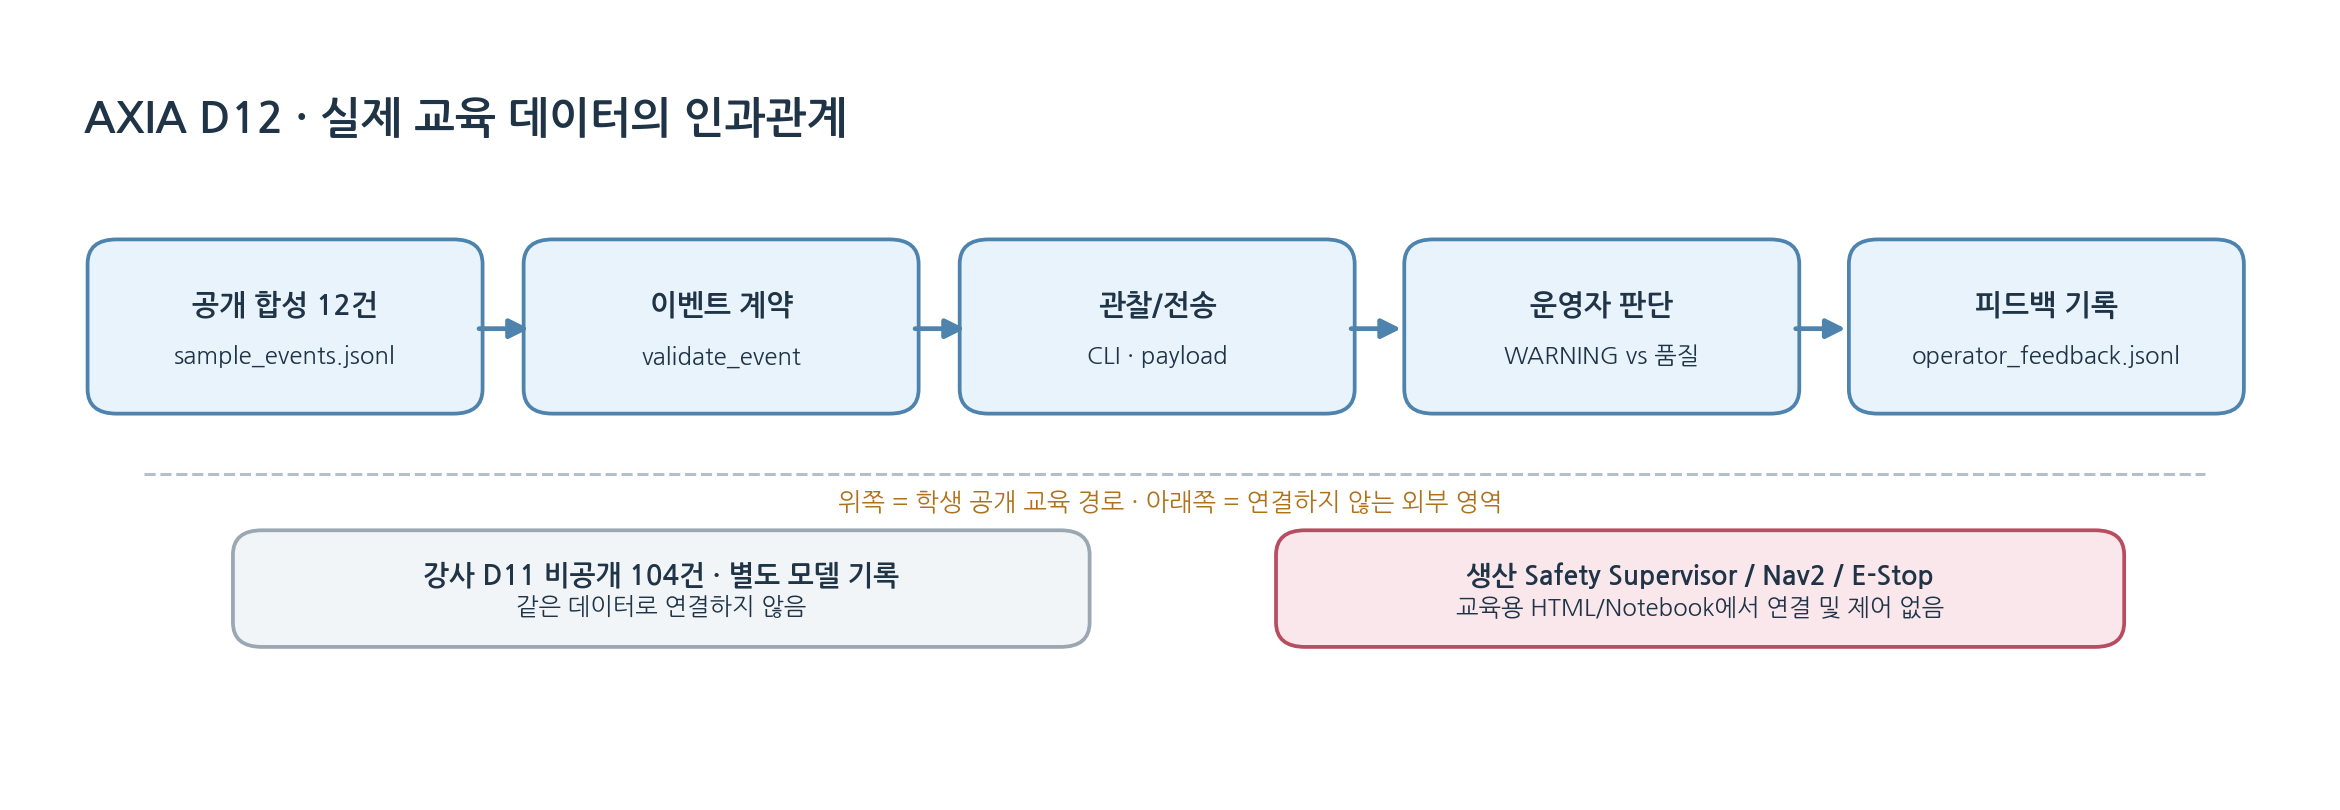

**그림 해설:** 파란 5단계만 이 Notebook에서 분석합니다. 아래 D11 강사 기록과 생산 제어 영역으로 화살표가 이어지지 않는 것이 핵심입니다.

## STEP 1. 공개 합성 이벤트 12건의 출처·shape 확인 (19:00–19:35)

**왜 필요한가?** “12건 중 경고 3건”이라는 결과가 먼저 보이더라도, **정확히 어떤 입력 파일에서 나왔는지** 확인하지 않으면 재현 가능한 증거가 아닙니다.  
**비유:** 사건 접수부에는 사건번호(event_id), 접수 대상(trace_id), 내용(score/level), 보존 원본 정보(source)가 있습니다. 먼저 사건부 자체를 검사합니다.

### 코드 실행 전 설명

- **입력:** 함께 제공된 `assets/sample_events.jsonl`, `assets/event_contract.py` — AXIA 학생 공개 저장소의 **동일 파일**입니다. 둘 다 **Git blob SHA1**로 원본 일치 여부를 기록했습니다.
- **핵심 API:** `Path.read_text`, `json.loads`, `Counter`, `hashlib.sha256`, `assert`.
- **shape:** `events`는 길이 12의 **list[dict]**이며 Tensor가 아닙니다. 필드는 각 객체에 13개입니다. 시간만 배열로 추출하면 `(12,)`입니다.
- **예상값:** 12건, 상태별 3건, 첫 WARNING `DEMO:TST_N_00:002`, 첫 품질 오류 `...:003`.
- **검증:** 파일이 존재하고 실제 바이트가 공개 Git blob SHA와 일치하며 모든 이벤트가 원본 계약을 통과하는지 검사합니다.

In [1]:
from pathlib import Path
import sys, platform, json, hashlib, collections

ROOT = Path.cwd()
ASSETS = ROOT / "assets"
assert ASSETS.is_dir(), "BLOCKED: lesson12 폴더에서 실행하고 assets/를 함께 보존하세요."
sys.path.insert(0, str(ASSETS))
import event_contract as contract  # 공개 D12 교육용 원본 계약 재사용

print("Python:", sys.version.split()[0], "OS:", platform.system())
print("Notebook 작업 폴더:", ROOT)
print("ROS/Gazebo 실제 실행: NOT_RUN (Python offline)")
assert sys.version_info >= (3, 10)
print("[PASS] 환경·소스 경로 확인")

Python: 3.13.5 OS: Linux
Notebook 작업 폴더: /mnt/data/lesson12
ROS/Gazebo 실제 실행: NOT_RUN (Python offline)
[PASS] 환경·소스 경로 확인


**출력 해설:** `Python`과 작업 폴더는 실행 PC에 따라 다릅니다. ROS/Gazebo를 실행하지 않았으므로 해당 범위는 **NOT_RUN**으로 출력합니다. 위 `[PASS]`는 Python 버전과 `assets/` 위치 확인에만 해당합니다.

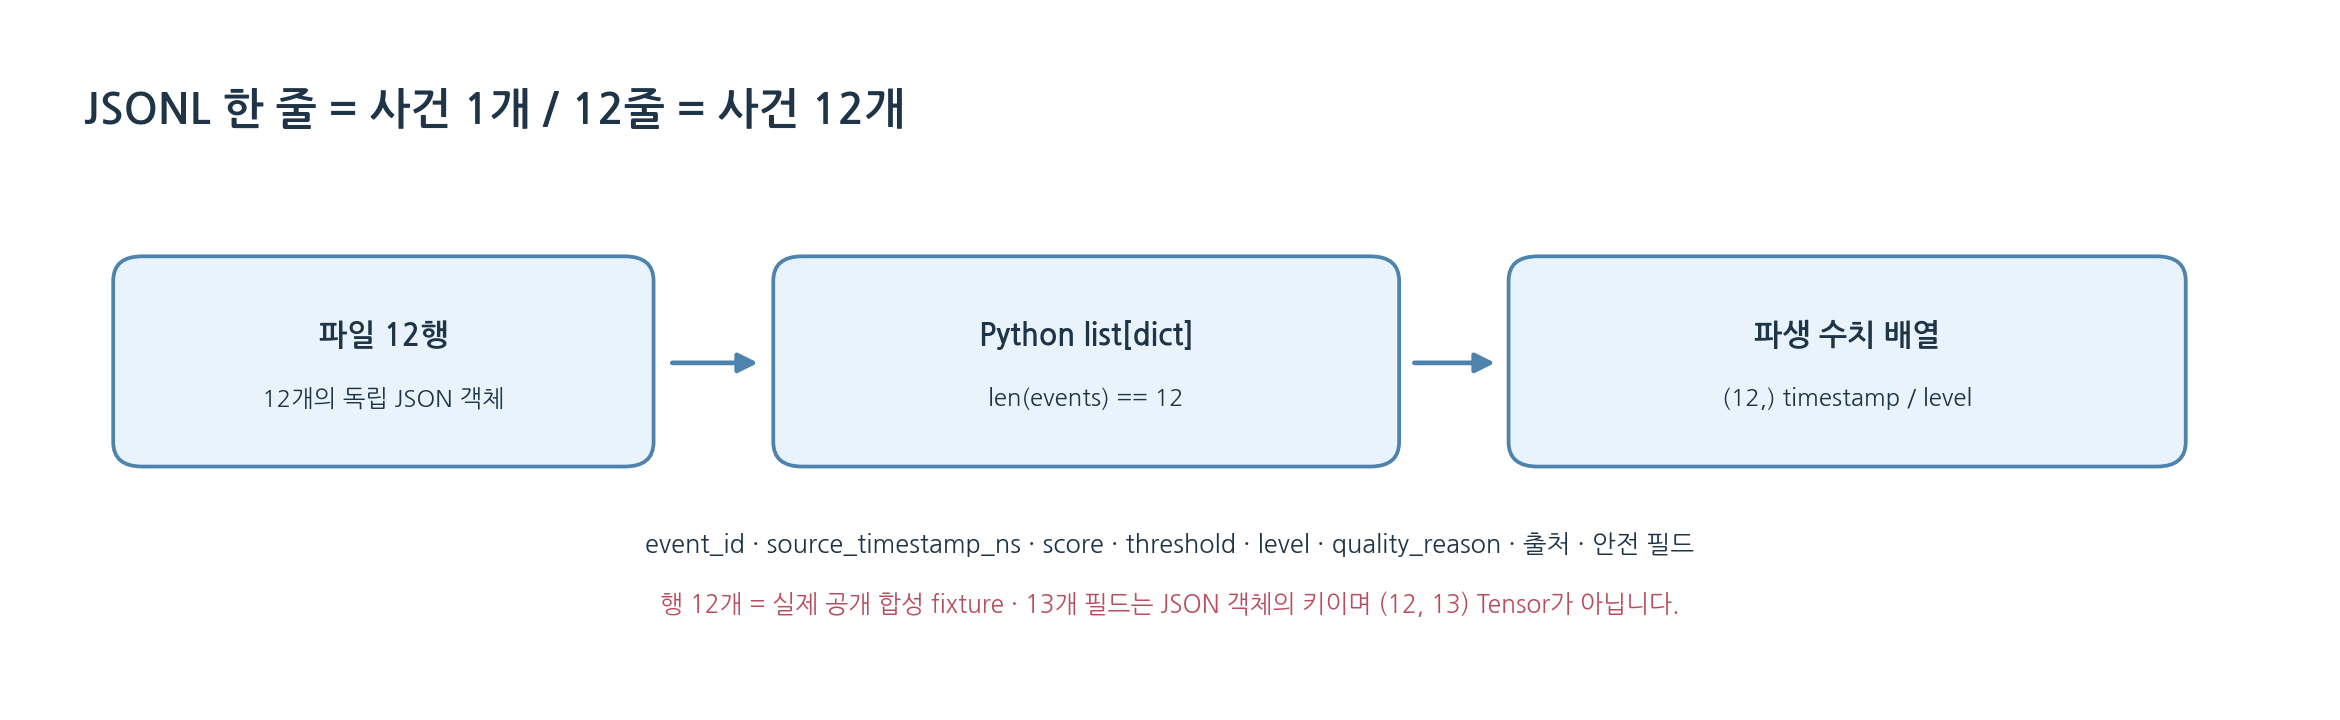

**그림 해설:** 13개 필드는 JSON 객체의 키 개수입니다. 아직 숫자 `(12,13)` Tensor로 만든 것이 아니며, `timestamps` 배열은 `(12,)`입니다.

In [2]:
file = ASSETS / "sample_events.jsonl"
raw = file.read_bytes()
actual_blob = hashlib.sha1(b"blob " + str(len(raw)).encode() + b"\0" + raw).hexdigest()
# GitHub 공개 학생 저장소 main 파일의 blob SHA — 제작 시 검수한 실제 출처
expected_blob = "07c7c282559870acdce4e44679873b930de7d2b1"
# Python 소스도 정확히 공개 원본과 일치하는지 별도 검사
source_bytes = (ASSETS / "event_contract.py").read_bytes()
source_blob = hashlib.sha1(b"blob " + str(len(source_bytes)).encode() + b"\0" + source_bytes).hexdigest()
assert actual_blob == expected_blob, "공개 이벤트 파일이 기준 원본과 다릅니다."
assert source_blob == "a00d2230be4d14d810b84db9938d4fac30e79b12"

events = [json.loads(line) for line in raw.decode("utf-8").splitlines() if line.strip()]
assert len(events) == 12
assert all(contract.validate_event(e) for e in events)
assert len(set(e["event_id"] for e in events)) == len(events)
assert all(e["control_authority"] is False and e["certified_estop"] is False for e in events)
counts = collections.Counter(e["level"] for e in events)
assert counts == {"NORMAL":3, "CAUTION":3, "WARNING":3, "INSUFFICIENT_DATA":3}
assert len(events[0].keys()) == 13
assert events[2]["event_id"] == "DEMO:TST_N_00:002"
assert events[3]["risk_score"] is None
print("출처: PUBLIC SYNTHETIC_COURSE_FIXTURE / EDUCATION_TRANSPORT_DEMO")
print("입력 SHA256:", hashlib.sha256(raw).hexdigest()[:16] + "… (실제 계산)")
print("이벤트 수:", len(events), "/ 객체 필드 수:", len(events[0]), "/ 상태별:", dict(counts))
print("첫 WARNING:", events[2]["event_id"], "0.9 > 0.5")
print("첫 품질 부족:", events[3]["event_id"], "score=None")
print("[PASS] 공개 원본 SHA · 12행 · 이벤트 계약 · 출처 · 비제어성")

출처: PUBLIC SYNTHETIC_COURSE_FIXTURE / EDUCATION_TRANSPORT_DEMO
입력 SHA256: 848969d9a42f2aa6… (실제 계산)
이벤트 수: 12 / 객체 필드 수: 13 / 상태별: {'NORMAL': 3, 'CAUTION': 3, 'WARNING': 3, 'INSUFFICIENT_DATA': 3}
첫 WARNING: DEMO:TST_N_00:002 0.9 > 0.5
첫 품질 부족: DEMO:TST_N_00:003 score=None
[PASS] 공개 원본 SHA · 12행 · 이벤트 계약 · 출처 · 비제어성


**실제 출력의 의미:** SHA는 **파일 바이트의 일치 여부**만 검증하며 데이터를 실제 로봇이 측정했음을 증명하지 않습니다. 12개 JSON 객체가 모두 계약을 통과하고 `control_authority=False`이므로 이 **교육용 데이터 자체에 제어 권한이 없음을 확인**했습니다. 안전 인증과는 다릅니다. `input_sha256='a'*64`는 공개 전송 샘플 내부의 **placeholder**로 실제 원본 CSV 해시가 아닙니다.

## STEP 2. 임계값·상태·데이터 품질을 구분하기 (19:35–20:00)

**문제:** `risk_score=0.9`, `threshold=0.5`가 나왔습니다. 경고로 분류할 수 있지만, **실제 Stop이 작동했다는 뜻일까요?** 아닙니다. 점수는 단지 교육용 판정 수치입니다.

### 계산 규칙(이번 교시 교육 프로필)

- 데이터 품질 부족 → `INSUFFICIENT_DATA`, score/threshold 모두 **None** (점수 없음).
- 유효 점수일 때: `risk > threshold` → **WARNING**.
- `0.8 × threshold ≤ risk ≤ threshold` → **CAUTION**.
- `risk < 0.8 × threshold` → **NORMAL**.

예를 들어 threshold=0.5이면 `0.8×0.5=0.4`가 주의 영역의 시작입니다. **0.40과 0.50은 CAUTION**, **0.51은 WARNING**, **0.39는 NORMAL**입니다. 

**기술적 경계:** 이 숫자 분류는 D12 실습용 정책 설명입니다. 공개 `validate_event`는 스키마·값·품질 계약을 검사하지만 **실제 임계값 재판정까지 수행하지는 않습니다**. 수치 분류 코드는 아래에서 별도로 구현해 비교합니다.

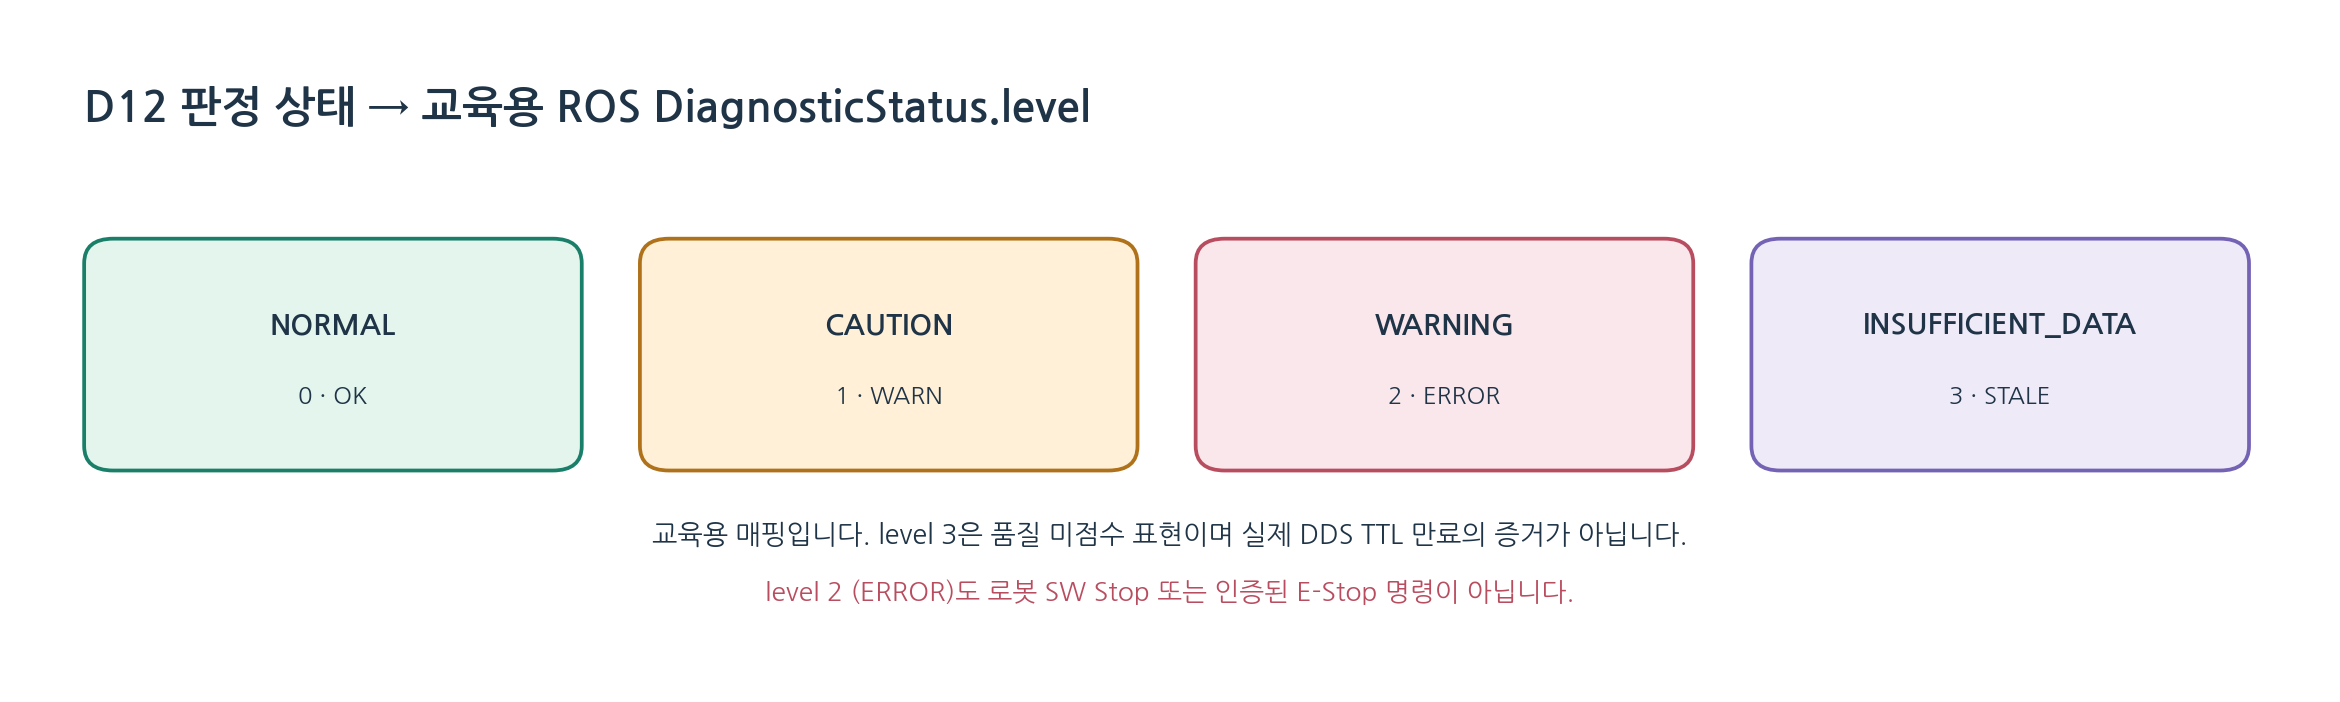

**그림 해설:** INSUFFICIENT_DATA를 3/STALE로 표시하는 것은 교육용 변환 규칙입니다. 실제 DDS 무수신이나 생산 Safety TTL 위반이 확인된 것이 아닙니다.

### 코드 실행 전 설명: 경계값·결측의 의미 검증

**입력:** 실제 공개 12건과 손으로 구성한 *경계 검사용 숫자 4개* (0.39, 0.40, 0.50, 0.51).  
**출력:** 4개 상태 수치와 실제 샘플의 상태 일치 개수.  
**검증:** 경계값은 부등식으로 직접 비교하고, 품질 부족 사건은 점수를 0으로 채우지 않습니다.

In [3]:
def course_level(score, threshold, quality_reason=None):
    """수업용 분류 로직. 실제 AI 모델 추론/안전제어가 아닙니다."""
    if quality_reason is not None:
        assert score is None and threshold is None
        return "INSUFFICIENT_DATA"
    assert score is not None and threshold is not None and threshold > 0
    if score > threshold:
        return "WARNING"
    if score >= 0.8 * threshold:
        return "CAUTION"
    return "NORMAL"

boundary = [(0.39, "NORMAL"), (0.40, "CAUTION"),
            (0.50, "CAUTION"), (0.51, "WARNING")]
for score, expected in boundary:
    got = course_level(score, 0.5)
    assert got == expected
    print(f"score={score:.2f}, threshold=0.50 → {got}")
assert course_level(None, None, "DEMO_SAMPLE_MISSING") == "INSUFFICIENT_DATA"
assert all(course_level(e["risk_score"], e["threshold"], e["quality_reason"]) == e["level"] for e in events)
print("[PASS] 경계 수치 4건 + 결측 1건 + 공개 이벤트 12건 판정 일치")

score=0.39, threshold=0.50 → NORMAL
score=0.40, threshold=0.50 → CAUTION
score=0.50, threshold=0.50 → CAUTION
score=0.51, threshold=0.50 → WARNING
[PASS] 경계 수치 4건 + 결측 1건 + 공개 이벤트 12건 판정 일치


**출력 해설:** 0.40은 `0.8×threshold`와 같으므로 CAUTION, 0.50은 threshold와 같아도 WARNING이 아니라 CAUTION입니다. 0.51은 threshold보다 커 WARNING입니다. 실수 계산에서는 부동소수점 오차가 생길 수 있어 실제 대규모 시스템은 허용오차 정책을 명시해야 하지만, 여기의 간단한 십진 예시는 교시 경계 설명용입니다.

### 다음은 “빈 데이터를 0점으로 바꾸면?”을 반례로 실험합니다

**문제:** 품질 실패 사건을 `risk_score=0.0`으로 조작한 다음 검사하면, 모델은 정상이라고 믿어도 될까요? **아닙니다.** 공개 계약은 품질 실패와 점수의 동시 존재를 거절합니다.

**예상 출력:** 변형 이벤트가 `ValueError`로 거절됩니다. 오류가 발생하는 것이 **의도한 시험**이며, 예외를 올바르게 잡은 경우에만 `[PASS]`를 표시합니다.

In [4]:
from copy import deepcopy
bad = deepcopy(events[3])
bad["risk_score"] = 0.0  # 잘못된 zero-fill 시연: 공개 원본 이벤트를 직접 바꾸지 않음
try:
    contract.validate_event(bad)
except ValueError as exc:
    assert "insufficient data" in str(exc)
    print("거절된 조작:", str(exc))
else:
    raise AssertionError("[FAIL] 품질 실패 zero-fill이 통과했습니다.")
assert events[3]["risk_score"] is None
print("[PASS] 품질 미점수는 실제 0점과 다르게 보존")

거절된 조작: insufficient data cannot be scored
[PASS] 품질 미점수는 실제 0점과 다르게 보존


**출력 해설:** `ValueError`를 잡았다는 것은 입력의 **데이터 계약 위반을 감지했다**는 뜻입니다. 실제 센서 누락 원인을 해결한 것은 아닙니다. `events[3]`의 원본은 None 상태로 그대로 남습니다.

## STEP 3. 시간이 다르면 지연도 다릅니다 — EventGate 실습 (20:00–20:20)

**문제:** “데이터가 300ms 늦었습니다.”라고 말하려면 **무슨 시계의 두 값을 비교했는지** 알아야 합니다.

- `source_timestamp_ns`: **합성 Trace 내부**의 0.0초, 0.1초…
- `DiagnosticArray.header.stamp`: 진단 메시지를 만들 때의 **ROS 시계**.
- `arrival_mono_ns`: 같은 수신 프로세스에서 기록한 **monotonic 단조 시계**.

서로 다른 기준 시각을 바로 빼는 계산은 **유효하지 않습니다**. 아래 숫자는 *손으로 설정한 수신 시각*으로 진행하며 실제 DDS 측정이 아닙니다.

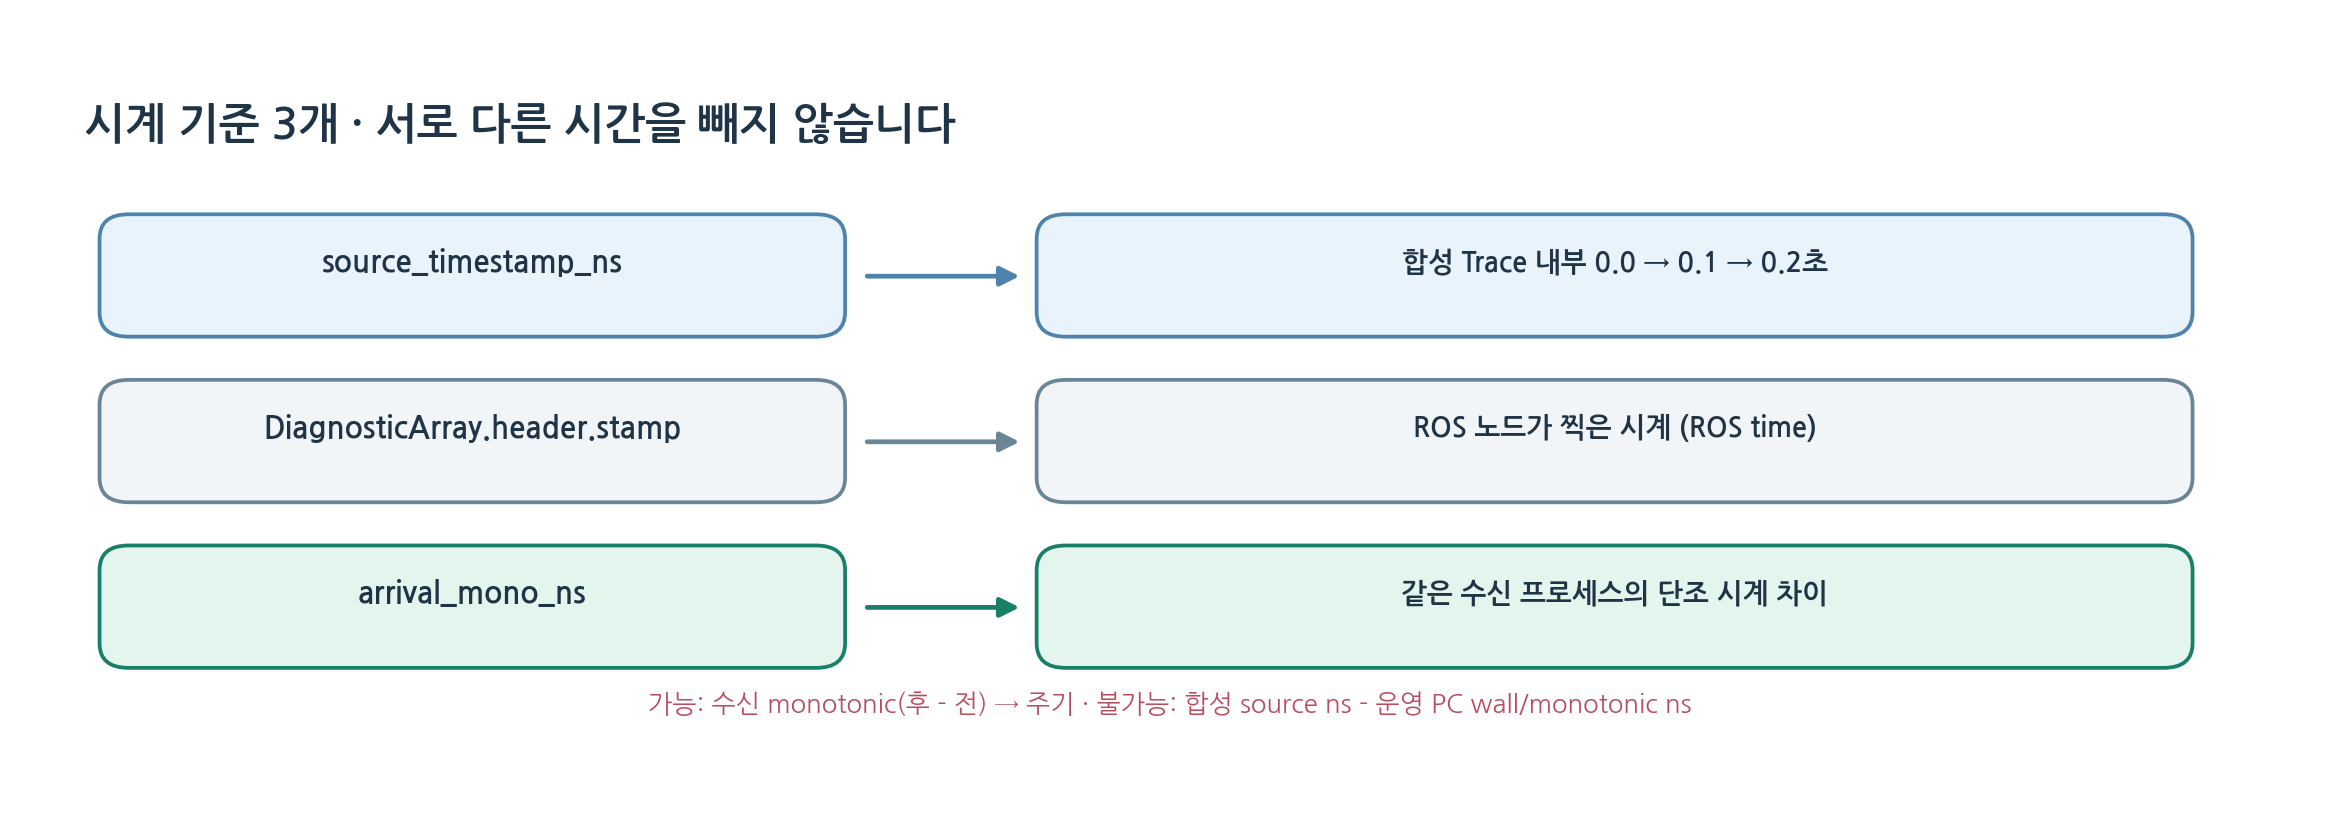

**그림 해설:** 수신 주기는 같은 monotonic 시계에서 앞뒤 수신 시각을 뺄 때만 의미가 있습니다. 이벤트 source와 로컬 wall clock을 감산하면 안 됩니다.

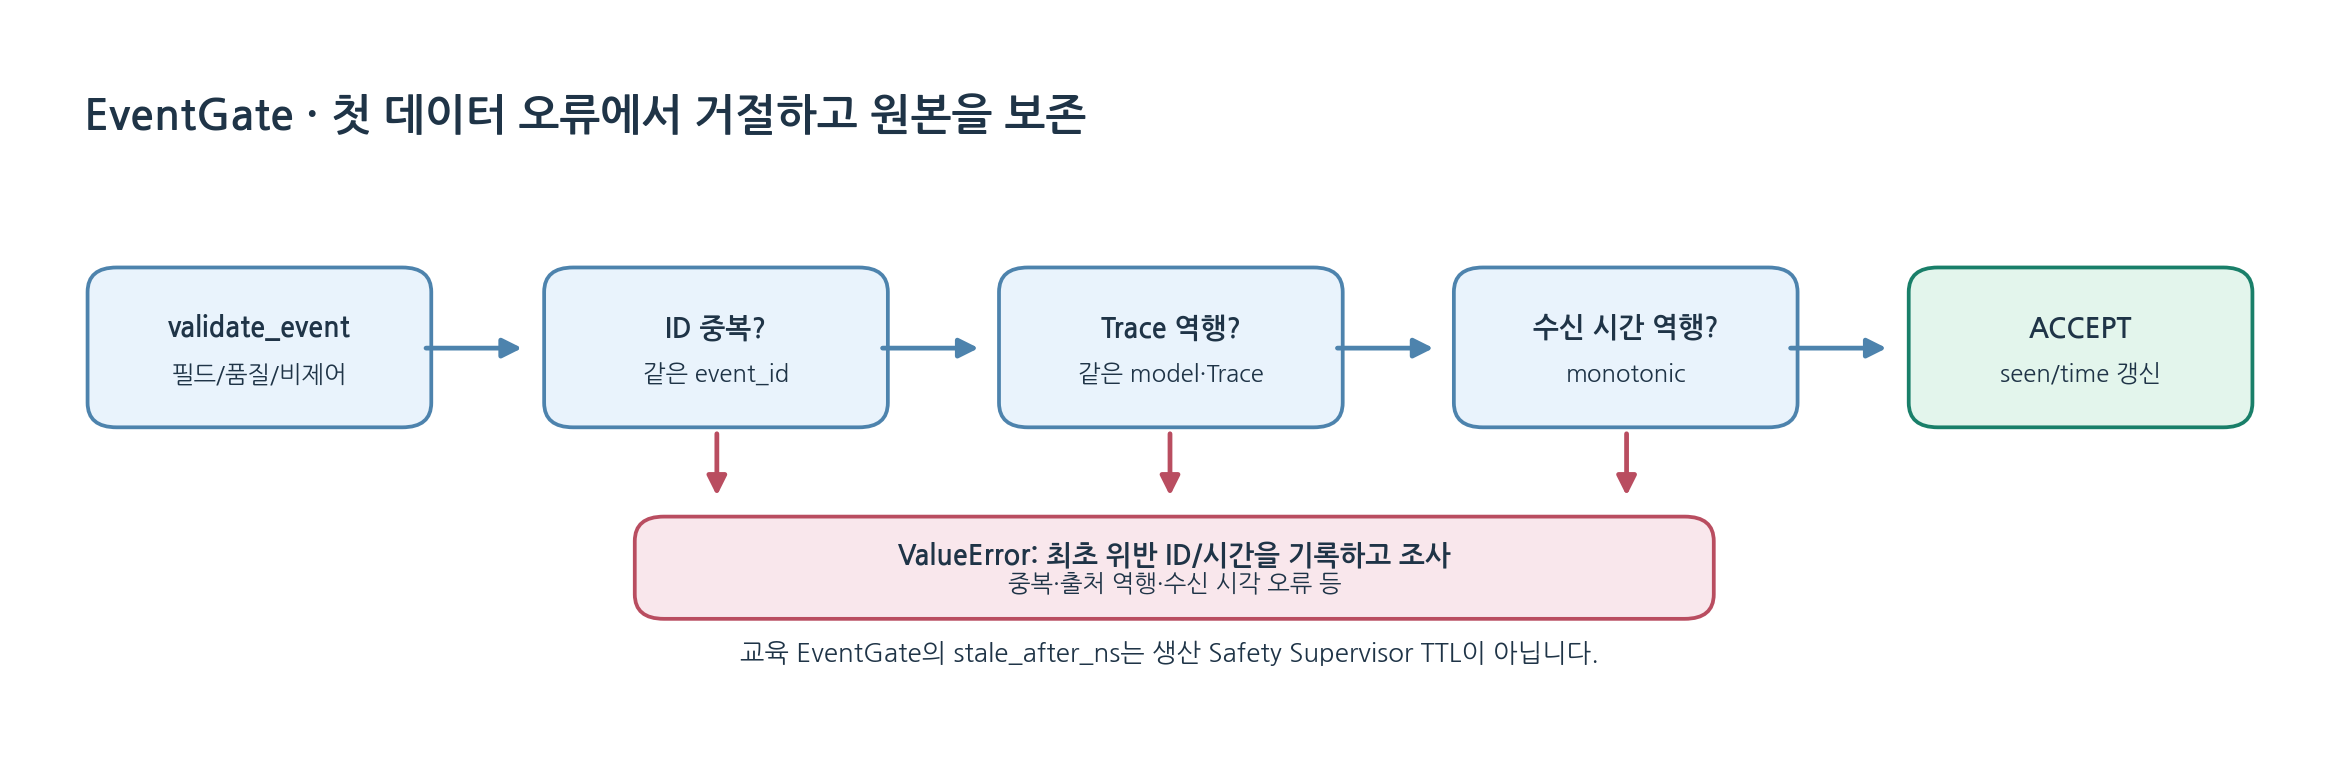

**그림 해설:** 이는 교육 데이터에 대한 품질 게이트입니다. 실제 안전 Supervisor TTL을 모니터링하는 코드와 동일하지 않습니다.

### 코드 실행 전 설명: 250ms 경계를 숫자로 계산합니다

**입력:** 같은 Trace의 첫 2건과 **인위적으로 설정한** 도착 monotonic 시각 1,000,000,000ns / 1,100,000,000ns.  
**핵심 API:** `EventGate.accept`, `EventGate.stale`.  
**계산:** 마지막 수신 1.1초 → 현재 1.350000001초이면 차이는 **250,000,001ns(250ms + 1ns)**. 임계값 250ms보다 크므로 stale=True.  
**검증:** ID 중복과 같은 Trace의 역행을 거절하는지 검증합니다. **실제 ROS 메시지를 수신하거나 TTL을 측정하지 않습니다.**

In [5]:
gate = contract.EventGate(stale_after_ns=250_000_000)
base_mono = 1_000_000_000
base_wall = 1_700_000_000_000_000_000  # 시험용 수치: 실제 UTC가 아님
for i in (0,1):
    assert gate.accept(events[i], base_mono + i*100_000_000,
                       base_wall + i*100_000_000) is True
assert gate.stale(1_350_000_000) is False  # == 250ms, 아직 초과 아님
assert gate.stale(1_350_000_001) is True   # == 250ms + 1ns

def expect_value_error(label, item, mono):
    try:
        gate.accept(item, mono, base_wall+300_000_000)
    except ValueError as exc:
        print(label, "→", str(exc))
        return str(exc)
    raise AssertionError("이벤트가 거절되지 않았음: " + label)

duplicate = expect_value_error("중복 사건", events[1], 1_200_000_000)
older = dict(events[2], event_id="TEST:OLDER", source_timestamp_ns=0)
retrograde = expect_value_error("Trace 시간 역행", older, 1_300_000_000)
assert "duplicate event_id" in duplicate
assert "out_of_order source trace" in retrograde
assert len(gate.seen) == 2
print("마지막 수신부터 250ms 초과 여부:", gate.stale(1_350_000_001))
print("[PASS] EventGate: 2건 허용 / 중복·역행 거절 / 250ms 초과 검증 (가상 수신시각)")

중복 사건 → duplicate event_id
Trace 시간 역행 → out_of_order source trace
마지막 수신부터 250ms 초과 여부: True
[PASS] EventGate: 2건 허용 / 중복·역행 거절 / 250ms 초과 검증 (가상 수신시각)


**출력 해설:** 중복과 역행은 **첫 데이터 오류**입니다. Exception을 정확히 확인하고 정상 시퀀스의 상태를 보존했기 때문에 통과합니다. `250ms`는 **이 코드가 설정한 교육용 EventGate 값**이며 실제 AXIA Safety Supervisor의 TTL, `/scan` 주기 또는 물리 정지시간 검증이 아닙니다.

## STEP 4. ROS 진단 메시지의 모양을 Python에서 관찰 (20:20–20:45)

**문제:** 사건을 운영 화면에 보내려면 ROS 2에서 무슨 메시지 타입을 사용해야 할까요? `diagnostic_msgs/msg/DiagnosticArray` 안에는 `Header header`와 `DiagnosticStatus[] status`가 들어갑니다. 한 상태에는 `level`, `name`, `message`, `hardware_id`, `values(KeyValue[])` 등이 들어갑니다.

**이번 실습은 ROS를 실행하지 않습니다.** 학생 공개 `event_contract.py`의 **`to_diagnostic_payload()`가 돌려주는 Python 사전**을 검사하여 실제 Bridge로 변환할 데이터를 이해합니다. 실제 `rclpy` Publisher·Subscriber는 별도 WSL2 Jazzy 실습으로 분리합니다.

- **Topic:** `/axia/education/diagnostics` (교육 전용)
- **교육 매핑:** NORMAL→0, CAUTION→1, WARNING→2, INSUFFICIENT_DATA→3.
- ROS 메시지의 `DiagnosticStatus.STALE=3`은 이 실습에서는 *품질 부족 표현*이며 실제 DDS TTL 만료라는 뜻이 아닙니다.
- ROS 2 `/rosout`은 **ROS logger의 로그 전송** 경로입니다. `DiagnosticArray` 발행만으로 사건 로그가 `/rosout`에 자동 생성되지 않습니다.

### 코드 실행 전 설명: 교육용 payload 검증

**입력:** 12건의 이미 검증된 `events`.  
**출력:** `payloads`라는 길이 12의 list[dict]와 0/1/2/3 매핑, 첫 WARNING의 상세 필드.  
**검증:** 다른 코드로 만든 가상의 ROS 네트워크 결과를 출력하는 것이 아니라, **원본 변환 함수의 실제 출력**을 읽고 레벨·토픽·비제어성을 확인합니다.

In [6]:
payloads = [contract.to_diagnostic_payload(e) for e in events]
levels = [p["level"] for p in payloads]
assert len(payloads) == 12
assert levels == [0,1,2,3] * 3
assert all(p["topic"] == "/axia/education/diagnostics" for p in payloads)
assert all(p["control_authority"] is False and p["certified_estop"] is False for p in payloads)
warning = payloads[2]
print("교육 토픽:", warning["topic"])
print("첫 WARNING payload 일부:")
print(json.dumps({k: warning[k] for k in ("event_id","level","message","hardware_id",
                                           "risk_score","threshold","control_authority")},
                 ensure_ascii=False, indent=2))
print("전체 매핑:", levels)
print("[PASS] Python payload 변환 12건 · 레벨·토픽·비제어성")

교육 토픽: /axia/education/diagnostics
첫 WARNING payload 일부:
{
  "event_id": "DEMO:TST_N_00:002",
  "level": 2,
  "message": "EDUCATION ONLY / NON-CERTIFIED: WARNING",
  "hardware_id": "SYNTHETIC_NO_HARDWARE",
  "risk_score": 0.9,
  "threshold": 0.5,
  "control_authority": false
}
전체 매핑: [0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3]
[PASS] Python payload 변환 12건 · 레벨·토픽·비제어성


**출력 해설:** Python dict의 `level=2`는 교육용 WARNING을 ROS 진단 level에 매핑하기 위한 정보입니다. **실제 `DiagnosticArray` 메시지를 publish했거나 DDS로 받은 증거는 아닙니다.** `hardware_id='SYNTHETIC_NO_HARDWARE'`가 실제 물리 센서가 아님을 다시 확인합니다.

### ROS 2 Jazzy PC를 가진 학생을 위한 *별도* 현장 단계(Notebook 실행 범위 밖)

아래 코드는 **터미널에서 실행하는 예시**입니다. 이 Notebook 실행에서는 호출하지 않으며, ROS가 없으면 **NOT_RUN**으로 유지합니다.

```bash
# WSL2 Ubuntu 24.04 + ROS 2 Jazzy가 설치된 경우에만
source /opt/ros/jazzy/setup.bash
export ROS_DOMAIN_ID=92
# 공개 AXIA 학생 저장소의 루트에서:
export AXIA_BLOCK_C_EVIDENCE_DIR="$HOME/axia_d12_course/student_evidence/ros_probe"
bash block_C/scripts/block_c_once.sh --ros-l1
cat "$AXIA_BLOCK_C_EVIDENCE_DIR/ros_l1/verdict.json"
```

**실제 출력 확인 조건:** 독립 Subscriber 8건, level 0/1/2/3, publisher 종료 상태, `period_min_ms/max_ms` **실측 수신 간격**. `/rosout`은 별도 logger 경로입니다. **CI의 과거 PASS는 학생 PC의 현재 PASS가 아닙니다.** 이 명령으로 Gazebo·Nav2·안전 TTL·E-Stop도 검증하지 않습니다.

## STEP 5. 사건 시간선과 분포 그래프 그리기 (20:45–21:20)

**문제:** 운영자는 WARNING이 모두 언제 나왔는지, 그 사이에 데이터 품질 문제가 끼어 있었는지를 한눈에 보고 싶습니다. 이제 문자열 수준의 사건 기록을 **숫자 배열과 시각화**로 바꿉니다.

**데이터 구조:** `timestamps`는 `(12,)` **float64 배열**이고, `scores`도 `(12,)`이지만 품질 부족 3건은 **NaN으로 표현해 그래프에서 제외**합니다. 입력 원본 JSON의 None을 0으로 고치지 않습니다.

**중요한 구분:** 여기서 0.0~1.1초는 합성 Trace 내부 타임스탬프이며 실제 로봇 주행 또는 실제 ROS latency가 아닙니다.

### 코드 실행 전 설명: Python list → NumPy 배열

**목적:** 시각화에 필요한 시간·점수·상태 배열을 만들고 dtype/shape를 검사합니다.  
**수식:** `time_sec = source_timestamp_ns × 10⁻⁹`. 예를 들어 200,000,000ns는 0.2초입니다.  
**예상:** shape `(12,)`, 0.0~1.1초, 품질 누락 3개, 정상 점수 9개.

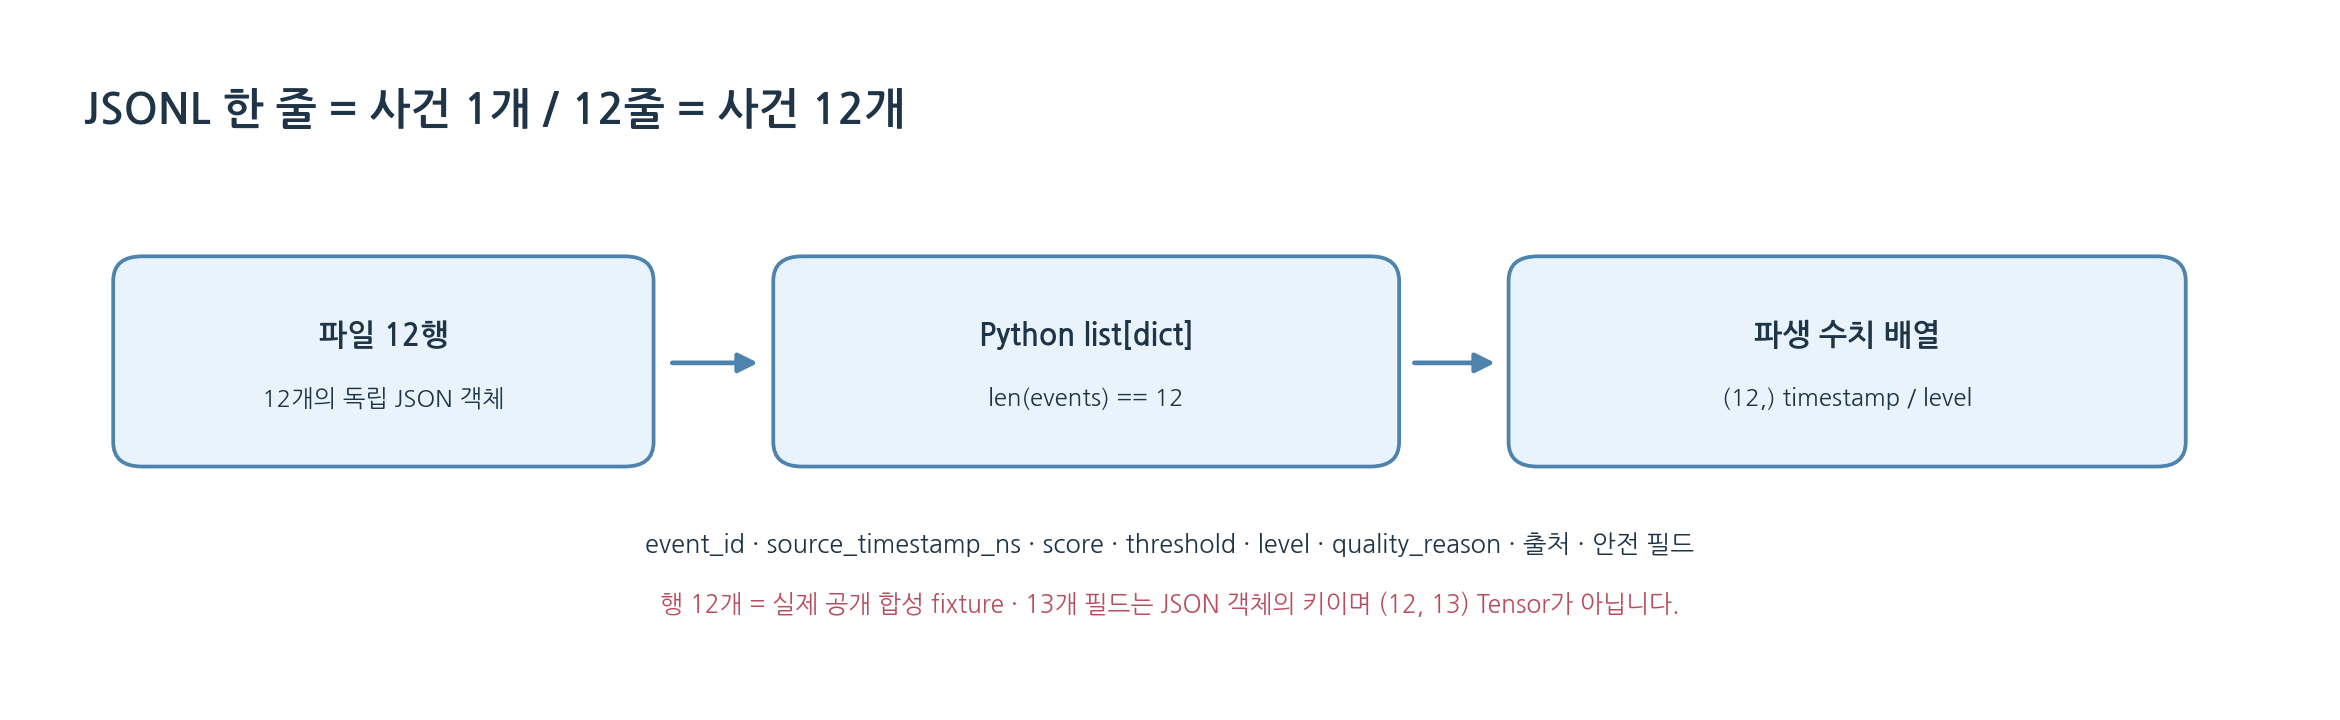

**그림 해설:** 같은 이벤트 객체에서 시간·상태·점수를 파생하지만 원본의 13개 키를 임의 Tensor shape로 해석하지 않습니다.

In [7]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
korean = next((name for name in ("NanumGothic", "Noto Sans CJK JP", "NanumBarunGothic")
               if name in available_fonts), None)
if korean:
    plt.rcParams["font.family"] = korean
else:
    print("한글 플롯 폰트 없음: 그래프 축·제목을 영어로 표시합니다 (Notebook 설명은 한국어 유지)")
plt.rcParams["axes.unicode_minus"] = False

seconds = np.asarray([e["source_timestamp_ns"] / 1_000_000_000 for e in events], dtype=np.float64)
scores = np.asarray([np.nan if e["risk_score"] is None else e["risk_score"] for e in events], dtype=np.float64)
status_codes = np.asarray([contract.LEVELS[e["level"]] for e in events], dtype=np.int64)
assert seconds.shape == scores.shape == status_codes.shape == (12,)
assert seconds.dtype == np.float64 and status_codes.dtype == np.int64
assert np.allclose(seconds, np.arange(12, dtype=float) / 10, atol=1e-12)
assert np.count_nonzero(np.isnan(scores)) == 3
assert np.count_nonzero(np.isfinite(scores)) == 9
print("시간 배열 shape/dtype:", seconds.shape, seconds.dtype)
print("상태 배열 shape/dtype:", status_codes.shape, status_codes.dtype)
print("가장 첫 WARNING 시각:", seconds[2], "sec (합성 Trace)")
print("점수 없음(NaN) 건수:", np.isnan(scores).sum())
print("[PASS] dtype·shape·합성 ns→sec 변환·결측 수량 일치")

시간 배열 shape/dtype: (12,) float64
상태 배열 shape/dtype: (12,) int64
가장 첫 WARNING 시각: 0.2 sec (합성 Trace)
점수 없음(NaN) 건수: 3
[PASS] dtype·shape·합성 ns→sec 변환·결측 수량 일치


**출력 해설:** `(12,)`는 **12개 원소를 가진 1차원 배열**입니다. 모델 Tensor shape `(batch, time, feature)`와 혼동하지 마세요. NaN은 **시각화를 위한 내부 표시**일 뿐 원본 JSONL의 `None`을 실제 이상 점수로 바꾼 것이 아닙니다. `np.allclose(..., atol=1e-12)`는 숫자 표현의 부동소수점 미세 오차를 허용합니다.

### 코드 실행 전 설명: 상태별 색상·임계값을 보여주는 사건 시간선

**관찰 질문:** `0.2s` WARNING 바로 다음 `0.3s` 사건은 다른 WARNING일까요? **품질 부족**입니다.  
**시각화 설계:** 정상=청록, 주의=황색, 경고=분홍, 품질 없음=보라. 품질 없음은 점수 0으로 표시하지 않고 **별도 높이**에서 보라색 × 기호로 표시합니다.

**예상:** 경고 위치 `0.2, 0.6, 1.0초`, 품질 부족 위치 `0.3, 0.7, 1.1초`.

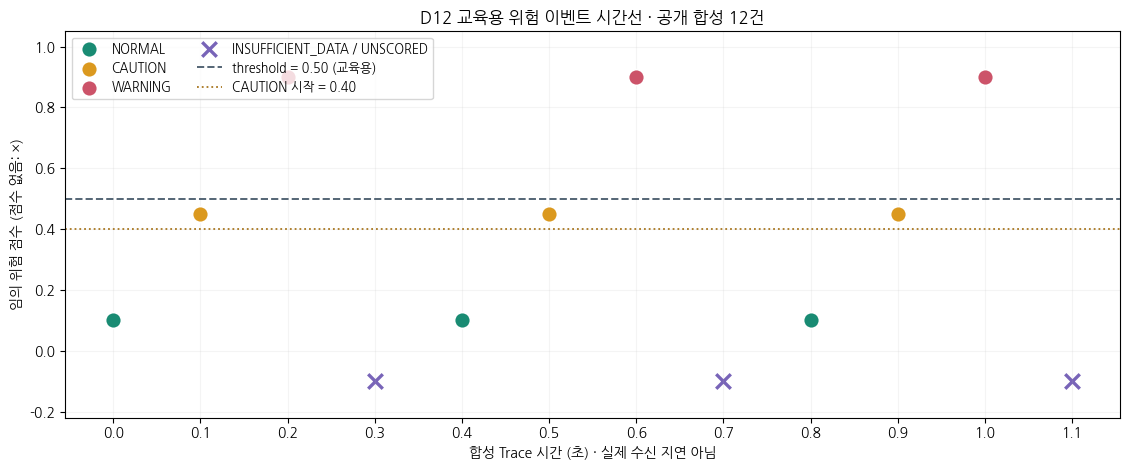

WARNING 합성 시각: [0.2, 0.6, 1.0]
품질 부족 합성 시각: [0.3, 0.7, 1.1]
[PASS] 시간선 사건 위치·라벨·비제어 해석 일치


In [8]:
colors = {"NORMAL":"#198b73", "CAUTION":"#db991f", "WARNING":"#cc5369", "INSUFFICIENT_DATA":"#7864b8"}
fig, ax = plt.subplots(figsize=(11.4, 4.8))
for level in contract.LEVELS:
    idx = np.array([e["level"] == level for e in events])
    if level == "INSUFFICIENT_DATA":
        ax.scatter(seconds[idx], np.full(idx.sum(), -0.10), marker="x", s=110,
                   linewidths=2.4, color=colors[level], label="INSUFFICIENT_DATA / UNSCORED")
    else:
        ax.scatter(seconds[idx], scores[idx], s=130, color=colors[level],
                   edgecolor="white", linewidth=1.2, label=level, zorder=3)
ax.axhline(0.5, ls="--", lw=1.4, color="#546575", label="threshold = 0.50 (교육용)")
ax.axhline(0.4, ls=":", lw=1.3, color="#a87620", label="CAUTION 시작 = 0.40")
ax.set(xlabel=("합성 Trace 시간 (초) · 실제 수신 지연 아님" if korean else "Synthetic trace time (sec) · NOT DDS latency"),
       ylabel=("임의 위험 점수 (점수 없음: ×)" if korean else "Synthetic risk score (missing: x)"),
       title=("D12 교육용 위험 이벤트 시간선 · 공개 합성 12건" if korean else "D12 Synthetic event timeline (12 samples)"))
ax.set_xticks(seconds)
ax.set_ylim(-0.22, 1.05)
ax.grid(alpha=.13)
ax.legend(ncol=2, fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(ROOT/"outputs"/"d12_event_timeline.png",dpi=170)
plt.show()
warning_times = seconds[status_codes == 2]
quality_times = seconds[status_codes == 3]
assert np.allclose(warning_times, [0.2,0.6,1.0])
assert np.allclose(quality_times, [0.3,0.7,1.1])
print("WARNING 합성 시각:", warning_times.tolist())
print("품질 부족 합성 시각:", quality_times.tolist())
print("[PASS] 시간선 사건 위치·라벨·비제어 해석 일치")

**출력 해설:** 점이 threshold 위에 있다고 해서 **실제 모터 고장 발생**이나 **정지 시간**을 측정한 것이 아닙니다. 이 그림은 **임의의 합성 Trace 1개**에서 어떤 교육용 수준이 언제 나타나는지를 보여줍니다. 품질 결손은 y=−0.1에 × 기호로 시각적으로 분리했으며, 이 음수는 점수가 아닙니다.

### 코드 실행 전 설명: 전체 사건 12건을 상태 비율로 비교

**비교 실험:** 네 상태가 각각 3건이라면 `3 / 12 × 100 = 25%`입니다. 숫자 계산과 실제 막대 높이가 일치해야 합니다.  
**판정:** 합계 12와 비율 합계 100%를 `assert`로 검사합니다. 실제 안전 성능·정밀도/재현율을 계산할 정답 라벨은 없습니다.

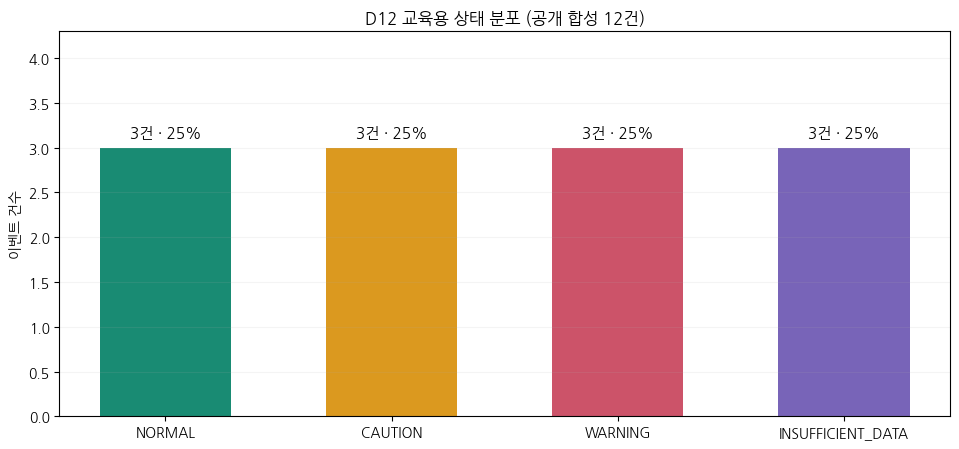

분포: {'NORMAL': 3, 'CAUTION': 3, 'WARNING': 3, 'INSUFFICIENT_DATA': 3}
전체 비율 합계: 100.0 %
[PASS] 합계·상태 비율 검증 12건/100%


In [9]:
ordered = list(contract.LEVELS.keys())
values = np.asarray([counts[k] for k in ordered], dtype=np.int64)
fractions = values / len(events) * 100
assert values.sum() == len(events) == 12
assert np.allclose(fractions, [25.0]*4, rtol=0, atol=1e-12)
assert np.isclose(fractions.sum(), 100.0, atol=1e-12)
fig, ax = plt.subplots(figsize=(9.7,4.6))
bars=ax.bar(ordered, values, color=[colors[k] for k in ordered], width=.58)
for bar,pct in zip(bars,fractions):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.12,
            f"{int(bar.get_height())}건 · {pct:.0f}%",ha="center",fontsize=11)
ax.set_ylim(0,4.3)
ax.set_ylabel("이벤트 건수" if korean else "Event count")
ax.set_title("D12 교육용 상태 분포 (공개 합성 12건)" if korean else "D12 Synthetic event levels (12 samples)")
ax.grid(axis='y',alpha=.13)
plt.tight_layout()
plt.savefig(ROOT/"outputs"/"d12_level_distribution.png",dpi=170)
plt.show()
print("분포:",dict(zip(ordered,values.tolist())))
print("전체 비율 합계:", round(float(fractions.sum()),2),"%")
print("[PASS] 합계·상태 비율 검증 12건/100%")

**출력 해설:** 네 상태가 각각 25%라는 사실은 **고정 교육 fixture의 구성**을 뜻합니다. 실제 운영 로봇의 위험 발생률은 알 수 없습니다. 고장 정답 라벨이 없으므로 이 숫자를 AI 모델 **정확도, F1, 탐지율**로 부르면 잘못입니다.

## STEP 6. 운영자의 판단을 별도 JSONL로 보존 (21:20–21:50)

**문제:** 시스템이 경고를 보여준 뒤, “이미 처리했습니다”라는 사람의 말만 남았다면 다음 운영자는 그 판단을 재검증할 수 없습니다. 사건 ID·조치·이유·기록 시각을 **원본 사건과 별도 파일**로 보존해야 합니다.

**오늘의 두 사건:**
1. `DEMO:TST_N_00:002` — score=0.9 > threshold=0.5이므로 `INVESTIGATE` (추가 조사)
2. `DEMO:TST_N_00:003` — score 없음·품질 결손으로 `CHECK_QUALITY` (품질 확인)

**반드시 포함:** `event_id`, `operator_action`, `reason`, `reviewed_at_utc`(실제 현재 UTC), `control_authority=False`.

**안전 경계:** 운영자 ACK나 피드백은 **SW Stop 해제·리셋·인증된 E-Stop 작동이 아닙니다**.

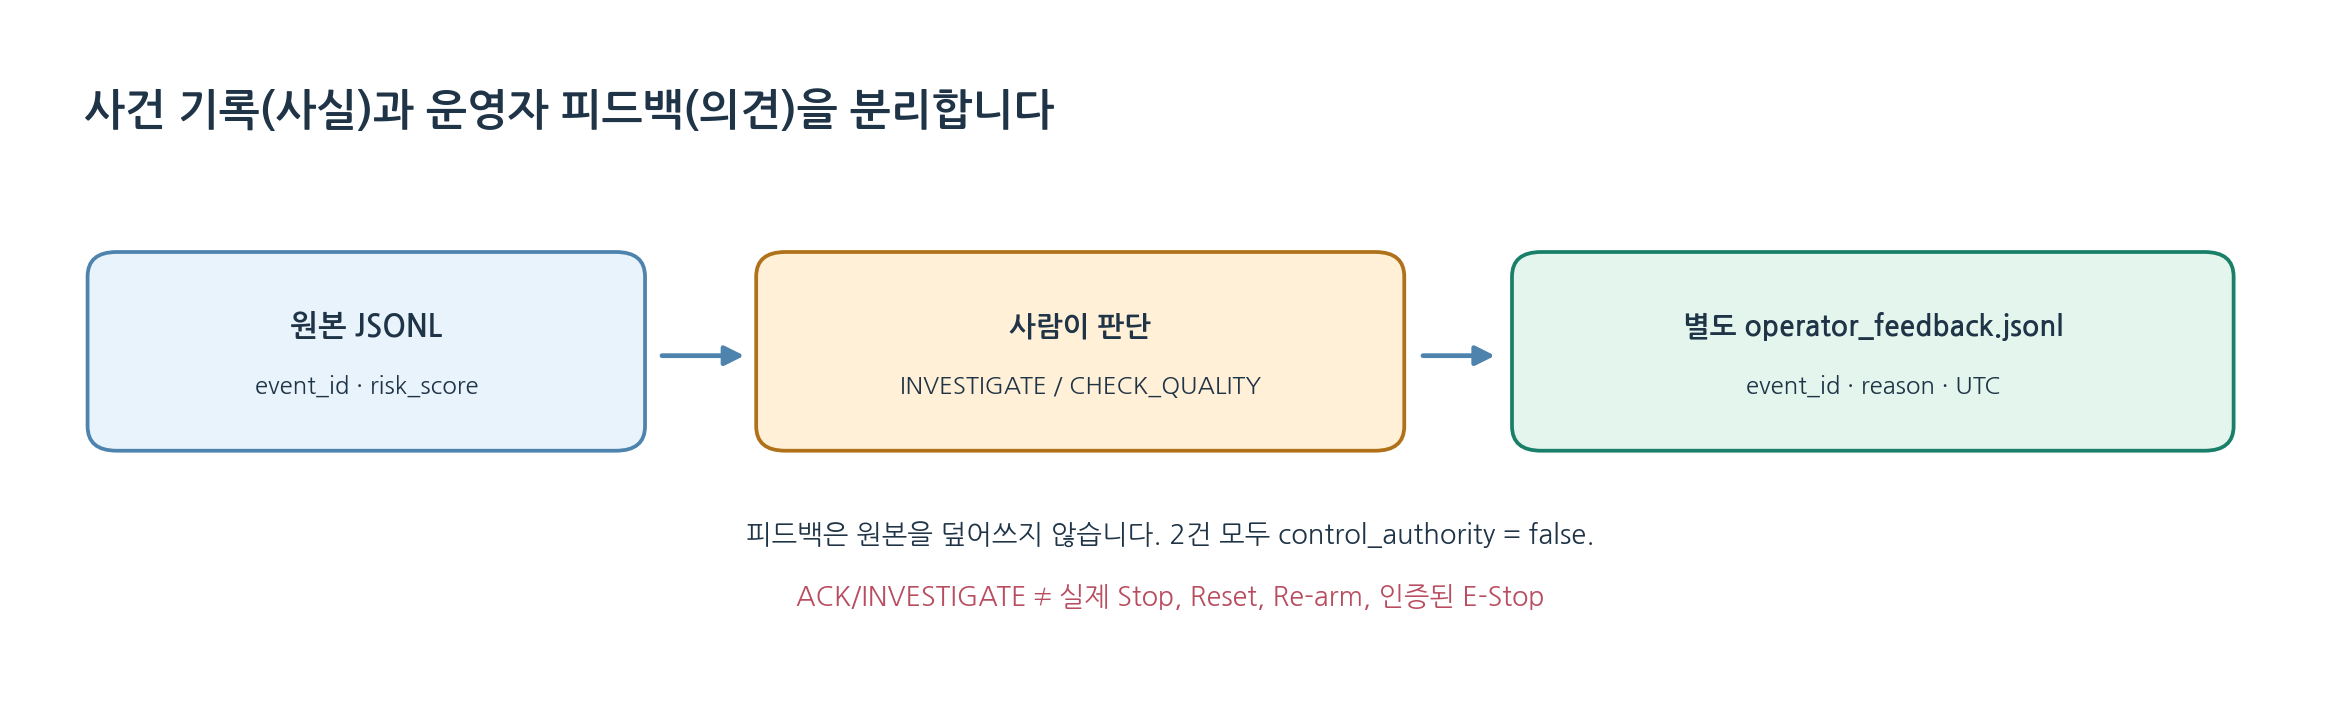

**그림 해설:** 이 구조는 사람의 판단을 보존하기 위한 교육용 기록 과정입니다. 로봇 제어 또는 안전 인증과 연결되지 않습니다.

### 코드 실행 전 설명: 실제 파일 쓰기·다시 읽기

**입력:** 공개 이벤트 2개, 운영자 조치 2종, 설명 문장.  
**출력:** `outputs/operator_feedback.jsonl` **실제 파일 2행**.  
**검증:** 파일을 새로 열어 JSON을 다시 파싱하고, 사건 ID가 원본과 맞으며, 중복 ID가 없고, 근거가 비어 있지 않으며, 제어 권한이 False인지 확인합니다.  
**주의:** `reviewed_at_utc`는 현재 PC의 UTC입니다. `source_timestamp_ns`(합성 시간)과 빼서 지연 시간을 계산하지 마세요.

In [10]:
from datetime import datetime, timezone

lookup = {e["event_id"]: e for e in events}
feedback = []
choices = [
    ("DEMO:TST_N_00:002", "INVESTIGATE", "합성 점수 0.90이 기준 0.50보다 큼. 실제 로봇 고장 원인은 미확인"),
    ("DEMO:TST_N_00:003", "CHECK_QUALITY", "합성 데이터의 점수가 없고 품질 사유가 있음. 입력 누락 원인 조사")
]
for event_id, action, reason in choices:
    assert event_id in lookup and reason.strip() and len(reason) >= 5
    feedback.append({
        "event_id": event_id, "operator_action": action, "reason": reason,
        "reviewed_at_utc": datetime.now(timezone.utc).isoformat(),
        "control_authority": False,
    })

output_dir = ROOT / "outputs"
output_dir.mkdir(exist_ok=True)
feedback_path = output_dir / "operator_feedback.jsonl"
feedback_path.write_text("".join(json.dumps(e, ensure_ascii=False) + "\n" for e in feedback), encoding="utf-8")
reloaded = [json.loads(line) for line in feedback_path.read_text(encoding="utf-8").splitlines() if line.strip()]
assert len(reloaded) == 2 and len({e["event_id"] for e in reloaded}) == 2
assert all(e["event_id"] in lookup and e["control_authority"] is False for e in reloaded)
assert all(e["reason"].strip() and datetime.fromisoformat(e["reviewed_at_utc"]).tzinfo is not None for e in reloaded)
print("저장 파일:", feedback_path.name)
for row in reloaded:
    print(row["event_id"], "→", row["operator_action"], "| control_authority=", row["control_authority"])
print("[PASS] 운영자 피드백 2건 실제 저장·재읽기·ID·비제어성")

저장 파일: operator_feedback.jsonl
DEMO:TST_N_00:002 → INVESTIGATE | control_authority= False
DEMO:TST_N_00:003 → CHECK_QUALITY | control_authority= False
[PASS] 운영자 피드백 2건 실제 저장·재읽기·ID·비제어성


**출력 해설:** `operator_feedback.jsonl` 파일이 실제로 쓰였고 **동일 파일을 다시 읽어 2건을 검사했습니다.** 사용자 기록 시간은 실제 실행 시각이므로 저장된 Notebook을 다른 날 열었을 때 이전 기록의 UTC와 실행 당시 UTC가 다를 수 있습니다. 새로운 파일의 존재와 현재 생성 시각은 실행한 PC에서 다시 확인하세요.

### 코드 실행 전 설명: 잘못된 피드백을 의도적으로 검사

이제 “존재하지 않는 사건 ID”와 “제어 권한 True”를 포함한 가짜 피드백을 만들어 **수업용 검증 함수가 거절하는지** 확인합니다. 원본 `operator_feedback.jsonl`은 수정하지 않습니다.

**예상 출력:** 두 입력 모두 `ValueError`로 거절되고, 실제 파일에 남은 2행은 그대로 유지됩니다.

In [11]:
def validate_feedback_item(row, events_by_id):
    if row["event_id"] not in events_by_id:
        raise ValueError("unknown event_id")
    if row.get("control_authority") is not False:
        raise ValueError("feedback cannot control robot")
    if not row.get("reason", "").strip():
        raise ValueError("empty operator reason")
    return True

wrong_id = dict(reloaded[0], event_id="DEMO:NOT_EXISTING")
wrong_control = dict(reloaded[0], control_authority=True)
for label, bad in (("없는 사건", wrong_id), ("제어권 오염", wrong_control)):
    try:
        validate_feedback_item(bad, lookup)
    except ValueError as exc:
        print(label, "입력 거절:", str(exc))
    else:
        raise AssertionError("[FAIL] 잘못된 운영자 기록을 허용했습니다")
assert all(validate_feedback_item(row, lookup) for row in reloaded)
assert len(feedback_path.read_text(encoding="utf-8").splitlines()) == 2
print("[PASS] 잘못된 운영자 기록 거절 · 기존 2건 원본 파일 보존")

없는 사건 입력 거절: unknown event_id
제어권 오염 입력 거절: feedback cannot control robot
[PASS] 잘못된 운영자 기록 거절 · 기존 2건 원본 파일 보존


**출력 해설:** `ValueError` 자체를 발생시키는 것이 목적이 아니라 **잘못된 입력이 원본 기록에 들어가지 못하도록 걸러냈는지** 확인하는 것입니다. `control_authority=False`라는 교육 필드만으로 실제 로봇 네트워크 접근제어가 완성되는 것은 아닙니다.

## 7. 전체 결과 요약 — 검증된 사실과 검증하지 않은 범위를 분리합니다

| 확인 항목 | 검증 방법 | 이 Notebook에서의 의미 |
|---|---|---|
| 실제 공개 데이터 12건 | 바이트 Git blob SHA·schema·건수 | **Python L0에서 검증** |
| 임계값/품질 경계 | 손계산·12건과 재판정 비교·zero-fill 거절 | **수업용 분류 규칙 검증** |
| 중복·Trace 시간 역행·250ms | `EventGate`에 가상 monotonic 시각 입력 | **교육 Gate 로직 검증**, 생산 TTL 아님 |
| ROS payload 변환 | Python dict / topic / level 비교 | **전송용 값의 구조만 검증**, DDS 송수신 아님 |
| 시간선·분포 | numpy shape·합계·그래프 실제 생성 | **합성 이벤트 시각화 검증** |
| 운영자 피드백 | 파일 작성 후 다시 열어 2건 검증 | **JSONL 파일 구조·연결 검증** |
| 실제 Jazzy Publisher·Subscriber | 이 Notebook에서 **NOT_RUN** | WSL2 Jazzy + 기존 `--ros-l1` 별도 실행 |
| Gazebo/Nav2/Stop/인증된 E-Stop | **NOT_RUN / 비대상** | 성공 주장 금지 |

**가장 중요한 문장:** `WARNING` 정보만으로는 로봇이 실제로 멈췄는지 알 수 없습니다. 데이터 품질, 사건 식별자, 시간 기준, 실제 운영자 판단을 별도로 보존해야 합니다.

## 8. 스스로 점검: 질문과 정답·해설

**Q1.** 공개 데이터가 12건이고 WARNING이 3건이라면 실제 로봇 고장이 3회 발생했다는 의미인가요?  
**정답:** 아닙니다. 이 12건은 `EDUCATION_TRANSPORT_DEMO` 합성 예제이며 모델 추론이나 실제 고장 검증과 다릅니다.

**Q2.** 임계값 0.5, 점수 0.50은 왜 WARNING이 아니고 CAUTION인가요?  
**정답:** 교시 규칙에서 WARNING은 **엄격한 초과(>)**이기 때문입니다. 0.50은 CAUTION의 상한 포함 영역입니다.

**Q3.** 데이터가 누락됐는데 점수를 0.0으로 고치면 안 되는 이유는?  
**정답:** 정상 점수와 미판정 상태는 의미가 다릅니다. `INSUFFICIENT_DATA`는 score/threshold가 None이어야 한다는 계약을 따릅니다.

**Q4.** `source_timestamp_ns`와 내 PC의 monotonic 값을 바로 빼도 되나요?  
**정답:** 안 됩니다. 하나는 합성 Trace의 상대 시각, 하나는 로컬 수신 단조 시계여서 기준점이 다릅니다.

**Q5.** `to_diagnostic_payload()`에서 level=2가 나왔으면 실제 ROS `/rosout`에 ERROR 로그가 전송되었나요?  
**정답:** 아닙니다. 여기서는 단지 Python dict를 만들었습니다. `DiagnosticArray`와 `/rosout` logger도 다른 경로입니다.

**Q6.** 왜 운영자 피드백을 원본 사건과 별도의 JSONL 파일로 저장하나요?  
**정답:** 원본 사실과 사람의 의견을 분리하고 `event_id`로 연결해 추적·인계를 가능하게 하기 위해서입니다.

**Q7.** `EventGate.stale_after_ns=250_000_000`을 시험했다면 Safety Supervisor 실제 TTL이 250ms라고 말할 수 있나요?  
**정답:** 말할 수 없습니다. 이 값은 실습에서 직접 설정한 가상 수신시간 시험용 임계값입니다.

## 9. 참고 자료와 재현성 선언

**직접 사용한 공개 AXIA 코드·데이터**
- [공개 `sample_events.jsonl` 12건](https://github.com/silverbjin/axia-robot-safety-student/blob/main/block_C/day12/ros_transport/sample_events.jsonl) — Git blob SHA: `07c7c282559870acdce4e44679873b930de7d2b1`
- [공개 `event_contract.py`](https://github.com/silverbjin/axia-robot-safety-student/blob/main/block_C/day12/ros_transport/event_contract.py) — Git blob SHA: `a00d2230be4d14d810b84db9938d4fac30e79b12`
- [학생 실제 HTML 관제 데모](https://github.com/silverbjin/axia-robot-safety-student/blob/main/block_C/day12/incident_command_center/AXIA_D12_INCIDENT_COMMAND_CENTER.html) — 본 Notebook과 같은 공개 합성 12건을 *별도 브라우저 UX*로 관찰.

**공식 기술 자료**
- [ROS 2 Jazzy Topics](https://docs.ros.org/en/jazzy/Tutorials/Beginner-CLI-Tools/Understanding-ROS2-Topics/Understanding-ROS2-Topics.html)
- [ROS 2 Jazzy Logging](https://docs.ros.org/en/jazzy/Concepts/Intermediate/About-Logging.html)
- [ROS 2 Jazzy QoS](https://docs.ros.org/en/jazzy/Concepts/Intermediate/About-Quality-of-Service-Settings.html)
- [ROS `DiagnosticArray` 메시지](https://github.com/ros2/common_interfaces/blob/rolling/diagnostic_msgs/msg/DiagnosticArray.msg)
- [ROS `DiagnosticStatus` 메시지](https://github.com/ros2/common_interfaces/blob/rolling/diagnostic_msgs/msg/DiagnosticStatus.msg)

**제작·실행 선언:** 사용자 제공 `lesson04-modern-llm-blocks(1).ipynb`의 **개념 → 코드 설명 → 실행 → 출력 설명** 구조와 attachment 그림 방식을 참고했습니다. 원본 LLM 결과값이나 모델 성능값은 재사용하지 않았습니다. 실제 실행 Python·라이브러리 버전·셀 개수·렌더링 결과는 동봉 `QA_REPORT.md`에서 확인합니다. 본 Notebook의 `[PASS]`는 Python으로 검증한 부분에만 해당합니다.

## 10. 학습 목표 최종 확인 — 오늘 작성한 증거를 30초로 설명해 보세요

“우리는 **공개 합성 이벤트 12건**을 원본 SHA로 확인하고, `event_id`와 `source_timestamp_ns`를 읽어 위험 후보와 품질 부족을 구분했습니다. Python에서 진단 payload와 중복·시간 경계를 검사하고, 합성 시간선과 상태 분포를 그림으로 만들었습니다. 운영자 피드백 **2건**을 파일로 저장하고 원본 ID와 연결 검증했습니다. **실제 ROS DDS·Gazebo·SW Stop·인증된 E-Stop은 이 Notebook에서 실행하지 않았습니다.**”

이 문장을 실제 실행 근거에 맞춰 자기 말로 설명할 수 있으면 두 학습목표를 달성한 것입니다.